In [83]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore", category=DeprecationWarning)
np.set_printoptions(suppress=True)


def Rz(theta):
    return np.array([[np.cos(theta), -np.sin(theta), 0], [np.sin(theta), np.cos(theta), 0], [0, 0, 1]])


def Ry(theta):
    return np.array([[np.cos(theta), 0, np.sin(theta)], [0, 1, 0], [-np.sin(theta), 0, np.cos(theta)]])


def Rx(theta):
    return np.array([[1, 0, 0], [0, np.cos(theta), -np.sin(theta)], [0, np.sin(theta), np.cos(theta)]])


# Apenas para visualização de um referencial no plano
def plot_frame(Porg, R, c=["r", "g"]):

    axis_size = 3.0
    axes = axis_size * R

    x_axis = np.array(axes[0:2, 0])
    y_axis = np.array(axes[0:2, 1])

    # X
    plt.quiver(*Porg[:2], *x_axis, color=c[0], angles="xy", scale_units="xy", scale=1)

    # Y
    plt.quiver(*Porg[:2], *y_axis, color=c[1], angles="xy", scale_units="xy", scale=1)

# Problema 1

A $Figura~1$ apresenta três sistemas de coordenadas \{A\}, \{B\} e \{C\} tais que:
- O sistema \{B\} é rotacionado de $\pi/6$ em $\hat{Z}_{A}$ de \{A\} e transladado em seguida de ${}^{A}T_{b}=[1, 2, 0]^{T}$
- O referencial \{C\} é rotacionado de $-\pi/4$ em $\hat{Z}_{A}$ de \{A\}, seguido de uma translação ${}^{A}T_{c}=[4, 1, 0]^{T}$

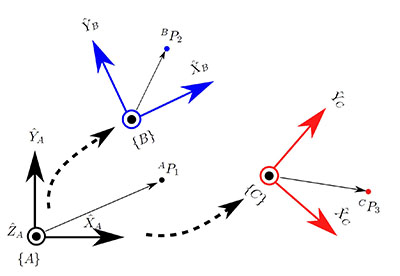

Determine:
- As transformações ${}_{B}^{A}T$, ${}_{C}^{A}T$ e ${}_{C}^{B}T$.
- As respectivas transformações inversas: ${}_{A}^{B}T$, ${}_{A}^{C}T$ e ${}_{B}^{C}T$.
- Dados três pontos ${}^{A}P_{1}=[1, 1, 1]^{T}$, ${}^{B}P_{2}=[0, 0, 1]^{T}$ e ${}^{C}P_{3}=[2, 2, 0]^{T}$, determine:
        ${}^{B}P_{1}$, ${}^{C}P_{1}$, ${}^{A}P_{2}$, ${}^{C}P_{2}$, ${}^{A}P_{3}$, ${}^{B}P_{3}$

Tab:
 [[ 0.8660254 -0.5        0.         1.       ]
 [ 0.5        0.8660254  0.         2.       ]
 [ 0.         0.         1.         0.       ]
 [ 0.         0.         0.         1.       ]]
Tac:
 [[ 0.70710678  0.70710678  0.          4.        ]
 [-0.70710678  0.70710678  0.          1.        ]
 [ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]]
Tbc:
 [[ 0.25881905  0.96592583  0.          2.09807621]
 [-0.96592583  0.25881905  0.         -2.3660254 ]
 [ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]]

T inversas:
Tba:
 [[ 0.8660254   0.5         0.         -1.8660254 ]
 [-0.5         0.8660254   0.         -1.23205081]
 [ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]]
Tca:
 [[ 0.70710678 -0.70710678  0.         -2.12132034]
 [ 0.70710678  0.70710678  0.         -3.53553391]
 [ 0.          0.          1.          0.        ]


(np.float64(-1.0), np.float64(8.0), np.float64(-2.0), np.float64(6.0))

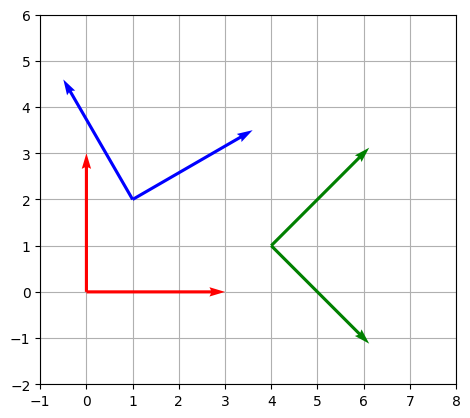

In [84]:
# Vetor auxiliar
aux = np.array([0, 0, 0, 1])

# Definindo Tab
pa_borg = np.array([1, 2, 0])
Rab = Rz(np.pi / 6.0)
Tab = np.column_stack((Rab, pa_borg))
Tab = np.row_stack((Tab, aux))
print("Tab:\n", Tab)

# Definindo Tac
pa_corg = np.array([4, 1, 0])
Rac = Rz(-np.pi / 4.0)
Tac = np.column_stack((Rac, pa_corg))
Tac = np.row_stack((Tac, aux))
print("Tac:\n", Tac)

# Definindo Tac
Tbc = np.linalg.inv(Tab) @ Tac
print("Tbc:\n", Tbc)

print("\nT inversas:")
print("Tba:\n", np.linalg.inv(Tab))
print("Tca:\n", np.linalg.inv(Tac))
print("Tcb:\n", np.linalg.inv(Tbc))

ap1 = np.array([1, 1, 1])
bp2 = np.array([0, 0, 1])
cp3 = np.array([2, 2, 1])

print("\nPosicoes:")
bp1 = np.linalg.inv(Tab) @ np.append(ap1, 1)
print("bp1:", bp1)

cp1 = np.linalg.inv(Tac) @ np.append(ap1, 1)
print("cp1:", cp1)

ap2 = Tab @ np.append(bp2, 1)
print("ap2:", ap2)

cp2 = np.linalg.inv(Tbc) @ np.append(bp2, 1)
print("cp2:", cp2)

ap3 = Tac @ np.append(cp3, 1)
print("ap3:", ap3)

bp3 = Tbc @ np.append(cp3, 1)
print("bp3:", bp3)


# Plotando os referenciais
plt.figure()

# Frame A
plot_frame(np.array([0, 0, 0]), np.identity(3), ["r", "r"])

# Frame A->B
plot_frame(pa_corg, Rac, ["g", "g"])

# Frame A->C
plot_frame(pa_borg, Rab, ["b", "b"])

plt.axis("scaled")
plt.grid(which="major", zorder=-1.0)
plt.axis((-1, 8, -2, 6))

# Problema 2

Obtenha as matrizes de transformação entre os sistemas de coordenadas \{A\}, \{B\} e \{C\}, ou seja ${}_{B}^{A}T$, ${}_{C}^{B}T$ e ${}_{C}^{A}T$, para os seguintes casos:

**a)** O referencial \{B\} é obtido pela rotação $\Theta_{1}$ em $\hat{Z}_{A}$ de \{A\}. O referencial \{C\} é obtido por uma rotação $\Theta_{2}$ de \{B\} em torno de $\hat{Y}_{B}$. Particularize as transformações para $\Theta_{1}=\pi/4$ e $\Theta_{2}=\pi/2$.

In [85]:
# Vetor auxiliar
aux = np.array([0, 0, 0, 1])

# 2a
Rab = Rz(np.pi / 4.0)
Tab = np.column_stack((Rab, np.array([0, 0, 0])))
Tab = np.row_stack((Tab, aux))
print("Tab:\n", Tab)

Rbc = Ry(np.pi / 2.0)
Tbc = np.column_stack((Rbc, np.array([0, 0, 0])))
Tbc = np.row_stack((Tbc, aux))
print("Tbc:\n", Tac)

print("Tac:\n", Tab @ Tbc)

Tab:
 [[ 0.70710678 -0.70710678  0.          0.        ]
 [ 0.70710678  0.70710678  0.          0.        ]
 [ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]]
Tbc:
 [[ 0.70710678  0.70710678  0.          4.        ]
 [-0.70710678  0.70710678  0.          1.        ]
 [ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]]
Tac:
 [[ 0.         -0.70710678  0.70710678  0.        ]
 [ 0.          0.70710678  0.70710678  0.        ]
 [-1.          0.          0.          0.        ]
 [ 0.          0.          0.          1.        ]]


**b)** O referencial \{B\} é obtido pela rotação $\Theta_{1}$ em $\hat{X}_{A}$ de \{A\}. O referencial \{C\} é obtido por uma rotação $\Theta_{2}$ de \{A\} em torno de $\hat{Z}_{A}$. Particularize as transformações para $\Theta_{1}=-\pi$ e $\Theta_{2}=\pi/4$.

In [86]:
# Vetor auxiliar
aux = np.array([0, 0, 0, 1])

# 2b
Rab = Rx(-np.pi)
Tab = np.column_stack((Rab, np.array([0, 0, 0])))
Tab = np.row_stack((Tab, aux))
print("Tab:\n", Tab)

Rbc = Rz(np.pi / 4.0)
Tbc = np.column_stack((Rbc, np.array([0, 0, 0])))
Tbc = np.row_stack((Tbc, aux))
print("Tbc:\n", Tac)

print("Tac:\n", Tab @ Tbc)

Tab:
 [[ 1.  0.  0.  0.]
 [ 0. -1.  0.  0.]
 [ 0. -0. -1.  0.]
 [ 0.  0.  0.  1.]]
Tbc:
 [[ 0.70710678  0.70710678  0.          4.        ]
 [-0.70710678  0.70710678  0.          1.        ]
 [ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]]
Tac:
 [[ 0.70710678 -0.70710678  0.          0.        ]
 [-0.70710678 -0.70710678  0.          0.        ]
 [-0.         -0.         -1.          0.        ]
 [ 0.          0.          0.          1.        ]]


**c)** O referencial \{B\} é obtido pela rotação $\Theta_{1}$ em $\hat{Y}_{A}$ de \{A\}. O referencial \{C\} é obtido por uma rotação $\Theta_{2}$ de \{B\} em torno de $\hat{X}_{A}$ de \{A\}. Particularize as transformações para $\Theta_{1}=\pi/2$ e $\Theta_{2}=-\pi$.

In [87]:
# Vetor auxiliar
aux = np.array([0, 0, 0, 1])

# 2c
Rab = Ry(np.pi / 2.0)
Tab = np.column_stack((Rab, np.array([0, 0, 0])))
Tab = np.row_stack((Tab, aux))
print("Tab:\n", Tab)

# O referencial $\{C\}$ é o resultado de aplicar uma rotação $\Theta_2$ em torno do eixo $\hat{X}_A$ (eixo do referencial fixo) sobre o referencial $\{B\}$.
# A regra fundamental da composição de rotações determina que, ao girar em torno de um eixo fixo/global, a nova matriz de rotação deve pré-multiplicar a transformação atual.

Tab_c = np.column_stack((Rx(-np.pi), np.array([0, 0, 0])))
Tab_c = np.row_stack((Tab_c, aux))

Tac = Tab_c @ Tab

Tbc = np.linalg.inv(Tab) @ Tac
print("Tbc:\n", Tbc)

Tab:
 [[ 0.  0.  1.  0.]
 [ 0.  1.  0.  0.]
 [-1.  0.  0.  0.]
 [ 0.  0.  0.  1.]]
Tbc:
 [[-1.  0.  0.  0.]
 [-0. -1.  0.  0.]
 [ 0. -0.  1.  0.]
 [ 0.  0.  0.  1.]]


# Problema 5

Considere o manipulador e os respectivos sistemas de coordenadas mostrados na $Figura~3$:

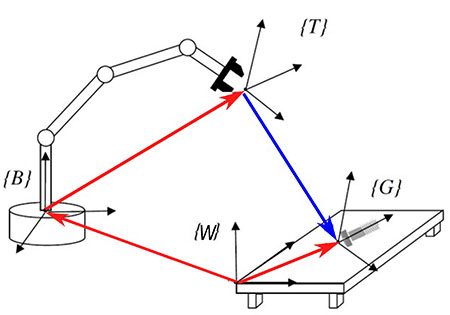

Assumindo os mapeamentos entre sistemas de coordenadas como sendo conhecidos, descreva:
- **a)** A matriz de mapeamento ${}_{W}^{T}T$, em função de ${}_{G}^{W}T$ e ${}_{G}^{T}T$.
    - ${}_{W}^{T}T = {}_{G}^{T}T {}_{W}^{G}T = {}_{G}^{T}T ({}_{G}^{W}T)^{-1}$
- **b)** A matriz de mapeamento ${}_{W}^{T}T$, em função de ${}_{B}^{W}T$ e ${}_{T}^{B}T$.
    - ${}_{W}^{T}T = ({}_{T}^{B}T)^{-1} ({}_{B}^{W}T)^{-1}$
- **c)** A matriz de mapeamento ${}_{G}^{B}T$, em função de ${}_{G}^{W}T$, ${}_{B}^{W}T$ e ${}_{T}^{B}T$.
    - ${}_{G}^{B}T = {}_{B}^{T}T {}_{W}^{B}T {}_{G}^{W}T = ({}_{T}^{B}T)^{-1} ({}_{B}^{W}T)^{-1} {}_{G}^{W}T$

